# ECON 422: Macroeconomics & Machine Learning
## Time Series: Trend and Seasonality with ML
This runnable notebook follows the attached lecture:
1. **Basics of trend and seasonality:** decomposition, trend forecasts, seasonal dummies, and worked examples.
2. **Combining with machine learning:** inference is deferred; forecasting uses **Random Forest and LASSO** in forecast combinations and additive models.

### Setup
Uncomment the installation line only if packages are missing. `%pip` installs into the current notebook kernel. Restart the kernel after installation if prompted.

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import curve_fit
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display, HTML

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})
SEED = 26

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted))**2)))
# Descriptive labels for tables and plots; short keys are used internally.
MODEL_LABELS = {'Trend + seasonality': 'Linear trend + monthly effects', 'Random Forest': 'Random Forest using time, month, promotion, and advertising', 'LASSO': 'LASSO penalizing time, month, and promotion/advertising features', 'Super learner: Random Forest': 'Weighted average: trend/month forecast + Random Forest forecast', 'Super learner: LASSO': 'Weighted average: trend/month forecast + LASSO forecast', 'Joint LASSO': 'Trend/month regression + LASSO for promotion and advertising', 'Joint Random Forest': 'Trend/month regression + Random Forest for promotion and advertising'}

# Show full labels and all columns in notebook tables.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

MODEL_LABELS['RF + LASSO'] = 'Weighted average: Random Forest forecast + LASSO forecast'

MODEL_LABELS.update({'RF + LASSO fitted together': 'LASSO + Random Forest fitted together using all predictors', 'Time + RF + LASSO': 'Trend/month regression + LASSO + Random Forest fitted together'})


# 1. Basics of Trend and Seasonality
## 1.1 See the components
The lecture writes $y_t=T_t+S_t+C_t+\varepsilon_t$. Trend changes the long-run level; seasonality repeats with the calendar; cycles are slower movements not tied to a fixed calendar; shocks are unexpected variation.

The smooth cycle below is only a visual illustration. We do not estimate an AR or MA model.

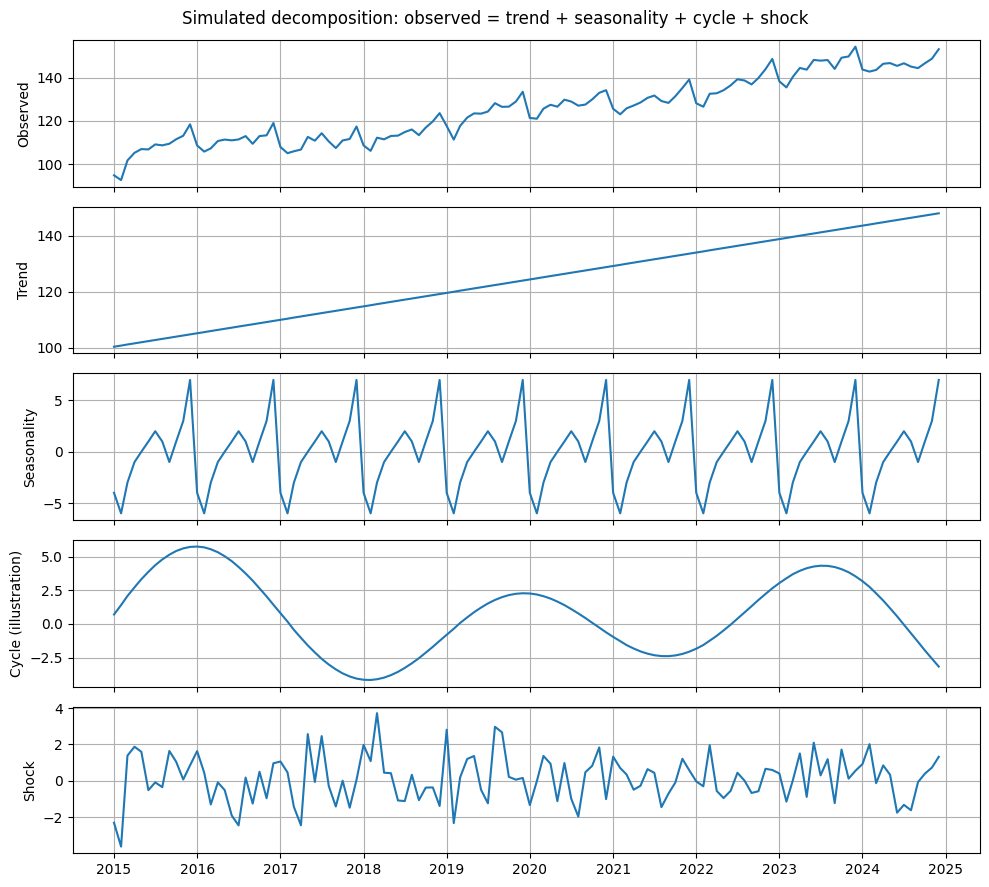

In [2]:
rng = np.random.default_rng(SEED)
dates = pd.date_range('2015-01-01', periods=120, freq='MS')
t = np.arange(1, len(dates) + 1)
season_pattern = np.array([-4, -6, -3, -1, 0, 1, 2, 1, -1, 1, 3, 7.])
trend = 100 + 0.4*t
season = season_pattern[dates.month - 1]
cycle = 4*np.sin(2*np.pi*t/47) + 2*np.sin(2*np.pi*t/71)
shock = rng.normal(0, 1.2, len(t))
y = trend + season + cycle + shock
fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
for ax, values, label in zip(axes, [y, trend, season, cycle, shock],
                              ['Observed', 'Trend', 'Seasonality', 'Cycle (illustration)', 'Shock']):
    ax.plot(dates, values)
    ax.set_ylabel(label)
fig.suptitle('Simulated decomposition: observed = trend + seasonality + cycle + shock')
plt.tight_layout()
plt.show()

## 1.2 Worked trend example from the lecture
Annual sales are 104, 105, 109, 112, 114, and 119. The time index counts years from the start of the sample. Fit the line, extend the index, and compute the lecture’s approximate prediction intervals.

In [3]:
annual = pd.DataFrame({'year': np.arange(2019, 2025), 't': np.arange(1, 7),
                       'sales': [104, 105, 109, 112, 114, 119]})
annual_fit = sm.OLS(annual.sales, sm.add_constant(annual[['t']])).fit()
future = pd.DataFrame({'t': [7, 8]})
future_design = sm.add_constant(future, has_constant='add')
pred = annual_fit.predict(future_design)
sigma = np.sqrt(annual_fit.mse_resid)
annual_forecast = pd.DataFrame({'year': [2025, 2026], 't': [7, 8], 'forecast': pred,
                               'lecture lower': pred - 1.96*sigma,
                               'lecture upper': pred + 1.96*sigma})
display(annual)
print(f'Fitted trend: {annual_fit.params.iloc[0]:.1f} + {annual_fit.params.iloc[1]:.1f} t')
print('Residuals:', np.round(annual_fit.resid.to_numpy(), 6), '| sigma =', round(sigma, 3))
display(annual_forecast.round(2))
# Optional comparison: exact normal-error OLS prediction intervals account for coefficient uncertainty.
full_interval = annual_fit.get_prediction(future_design).summary_frame(alpha=0.05)
display(full_interval[['mean', 'obs_ci_lower', 'obs_ci_upper']].round(2))
assert np.allclose(annual_fit.params, [100, 3])
assert np.allclose(pred, [121, 124])

,year,t,sales
0,2019,1,104
1,2020,2,105
2,2021,3,109
3,2022,4,112
4,2023,5,114
5,2024,6,119


Fitted trend: 100.0 + 3.0 t
Residuals: [ 1. -1.  0.  0. -1.  1.] | sigma = 1.0


,year,t,forecast,lecture lower,lecture upper
0,2025,7,121.0,119.04,122.96
1,2026,8,124.0,122.04,125.96


,mean,obs_ci_lower,obs_ci_upper
0,121.0,117.21,124.79
1,124.0,119.77,128.23


The lecture’s constant-width bands ignore coefficient uncertainty. The second table includes it under independent normal errors and the correct linear model; with only six observations, these intervals are substantially wider. Neither formula automatically handles persistent errors.

## 1.3 Linear, quadratic, and exponential trends
Use a new positive simulated series with curvature. Fit through the end of the estimation sample and compare on later observations. NLS fits the exponential in **levels**. The log-linear fit is displayed separately because its fit statistics are on a different scale.

,Estimation RMSE,AIC/T,BIC/T,Later-period RMSE
Model,,,,
Linear,7.279,4.007,4.057,21.967
Quadratic,1.895,1.334,1.408,1.592
Exponential NLS,2.761,2.068,2.118,10.133


Log-linear coefficients (log outcome): [3.0036 0.0186]


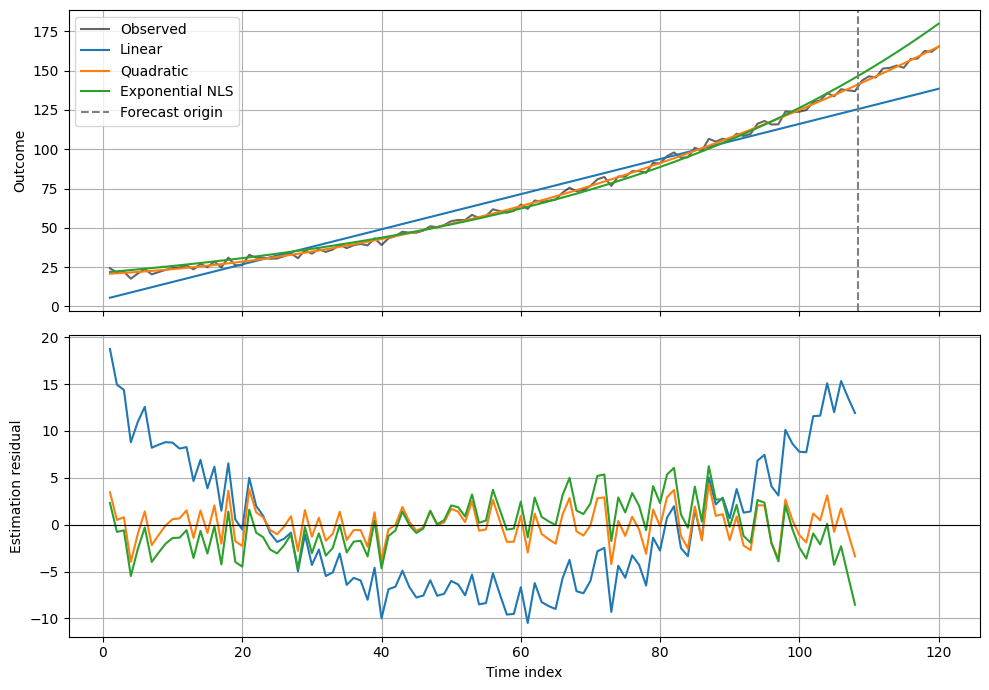

In [4]:
rng_trend = np.random.default_rng(422)
tt = np.arange(1, 121, dtype=float)
yy = 20 + .25*tt + .008*tt**2 + rng_trend.normal(0, 2, len(tt))
cut = 108
linear_X = np.column_stack([np.ones(len(tt)), tt])
quad_X = np.column_stack([np.ones(len(tt)), tt, tt**2])
linear_fit = sm.OLS(yy[:cut], linear_X[:cut]).fit()
quad_fit = sm.OLS(yy[:cut], quad_X[:cut]).fit()
def exp_curve(time, a, b):
    return a*np.exp(b*time)
p_exp, _ = curve_fit(exp_curve, tt[:cut], yy[:cut], p0=[20, .015], maxfev=10000)
log_fit = sm.OLS(np.log(yy[:cut]), linear_X[:cut]).fit()
trend_predictions = {'Linear': linear_fit.predict(linear_X),
                     'Quadratic': quad_fit.predict(quad_X),
                     'Exponential NLS': exp_curve(tt, *p_exp)}
# Gaussian level-error criteria, omitting a common constant; k counts mean coefficients.
rows = []
for name, fitted in trend_predictions.items():
    k = 3 if name == 'Quadratic' else 2
    ssr = np.sum((yy[:cut] - fitted[:cut])**2)
    rows.append({'Model': name, 'Estimation RMSE': rmse(yy[:cut], fitted[:cut]),
                 'AIC/T': np.log(ssr/cut) + 2*k/cut,
                 'BIC/T': np.log(ssr/cut) + k*np.log(cut)/cut,
                 'Later-period RMSE': rmse(yy[cut:], fitted[cut:])})
display(pd.DataFrame(rows).set_index('Model').round(3))
print('Log-linear coefficients (log outcome):', np.round(log_fit.params, 4))
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(tt, yy, color='black', label='Observed', alpha=.6)
for name, fitted in trend_predictions.items():
    axes[0].plot(tt, fitted, label=name)
    axes[1].plot(tt[:cut], yy[:cut]-fitted[:cut], label=name)
axes[0].axvline(cut+.5, color='gray', linestyle='--', label='Forecast origin')
axes[0].legend(); axes[0].set_ylabel('Outcome')
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(xlabel='Time index', ylabel='Estimation residual')
plt.tight_layout(); plt.show()

## 1.4 Worked seasonal example from the lecture
Use all four quarterly dummies with **no intercept**, or an intercept and three dummies. The full-dummy coefficients are the quarter-specific means. The future quarter is known from the calendar.

In [5]:
quarterly = pd.DataFrame({'year': np.repeat([2022, 2023, 2024], 4),
    'quarter': np.tile([1, 2, 3, 4], 3),
    'sales': [21, 32, 44, 29, 19, 33, 45, 28, 20, 31, 46, 27]})
Q = np.eye(4)[quarterly.quarter.to_numpy()-1]
season_fit = sm.OLS(quarterly.sales, Q).fit()  # no additional intercept
season_sigma = np.sqrt(season_fit.mse_resid)
season_forecast = season_fit.predict(np.eye(4))
display(quarterly.pivot(index='year', columns='quarter', values='sales'))
display(pd.DataFrame({'2025 quarter': [1, 2, 3, 4], 'forecast': season_forecast,
                     'lecture lower': season_forecast-1.96*season_sigma,
                     'lecture upper': season_forecast+1.96*season_sigma}).round(2))
print('Seasonal factors:', season_fit.params.to_numpy())
print('Reference-quarter differences:', season_fit.params.to_numpy()[1:]-season_fit.params.iloc[0])
assert np.allclose(season_forecast, [20, 32, 45, 28])
assert np.isclose(season_sigma, 1)

quarter,1,2,3,4
year,,,,
2022,21,32,44,29
2023,19,33,45,28
2024,20,31,46,27


,2025 quarter,forecast,lecture lower,lecture upper
0,1,20.0,18.04,21.96
1,2,32.0,30.04,33.96
2,3,45.0,43.04,46.96
3,4,28.0,26.04,29.96


Seasonal factors: [20. 32. 45. 28.]
Reference-quarter differences: [12. 25.  8.]


## 1.5 Cycles: a preview only
A fixed trend and calendar pattern may leave slow movements unexplained. The decomposition plot illustrates this possibility. We return to models of these movements later; no AR, MA, or DML estimation is needed in this notebook.

# 2. Combining with Machine Learning
## 2.1 Estimation and Inference
As in the lecture, **DML for time series is deferred until after AR models**.

## 2.2 Forecasting
We compare a trend-and-seasonality baseline, standalone Random Forest and LASSO, two super learners, and additive combinations. Every model uses only information available at the forecast origin.

### 2.2.1 Forecasting data and information available
Simulate 12 years of monthly sales with a richer nonlinear DGP:
$$y_t=80+0.4t+S_t+q(P_t,A_t)+\varepsilon_t,$$
$$\begin{aligned}q(P,A)={}&6P+3A+4(A^2-1/3)-3A^3+5(A^4-1/5)\\
&+4(A^6-1/7)+2\sin(\pi A)+P(2A-3A^2+2A^3).\end{aligned}$$
$P_t$ is a planned promotion and $A_t$ a centered advertising-budget index. Assume both are known for the next 12 months when forecasts are made. Unknown future predictors would otherwise need forecasts of their own.

**The estimator does not receive the true function.** Both LASSO models automatically generate candidate polynomial powers and interactions from the raw promotion and advertising variables. They choose a maximum degree from **2, 3, and 4** and a penalty using earlier forecast errors. The DGP contains a sixth-order term and a sine term, so the candidate features do not exactly reproduce it. Random Forest uses the raw predictors. All models are compared on the same held-out year; no winner is guaranteed.


In [6]:
rng_ml = np.random.default_rng(SEED)
N = 144
frame = pd.DataFrame({'date': pd.date_range('2013-01-01', periods=N, freq='MS'),
                      't': np.arange(1, N+1)})
frame['month'] = frame.date.dt.month
frame['promotion'] = rng_ml.binomial(1, .3, N)
frame['ad'] = rng_ml.uniform(-1, 1, N)
frame['y'] = (80 + .4*frame.t + season_pattern[frame.month.to_numpy()-1]
              + 6*frame.promotion + 3*frame.ad + 4*(frame.ad**2-1/3)
              - 3*frame.ad**3 + 5*(frame.ad**4-1/5)
              + 4*(frame.ad**6-1/7) + 2*np.sin(np.pi*frame.ad)
              + frame.promotion*(2*frame.ad-3*frame.ad**2+2*frame.ad**3) + rng_ml.normal(0, 1.5, N))
feature_names = ['t', 'month', 'promotion', 'ad']
X_all = frame[feature_names].copy()
y_all = frame.y.to_numpy()
TEST_HORIZON = 12
split = N - TEST_HORIZON
X_est, X_test = X_all.iloc[:split].copy(), X_all.iloc[split:].copy()
y_est, y_test = y_all[:split].copy(), y_all[split:].copy()
# Four historical 12-month evaluation blocks, all before the final test year.
folds = list(TimeSeriesSplit(n_splits=4, test_size=12).split(X_est))
fold_table = []
for k, (tr, va) in enumerate(folds, 1):
    assert tr.max() < va.min() and va.max() < split
    fold_table.append({'Fold': k, 'Estimation start': frame.date.iloc[tr[0]],
                      'Estimation end': frame.date.iloc[tr[-1]],
                      'Evaluation start': frame.date.iloc[va[0]],
                      'Evaluation end': frame.date.iloc[va[-1]]})
display(pd.DataFrame(fold_table))
print('Final test period:', frame.date.iloc[split].date(), 'to', frame.date.iloc[-1].date())

,Fold,Estimation start,Estimation end,Evaluation start,Evaluation end
0,1,2013-01-01,2019-12-01,2020-01-01,2020-12-01
1,2,2013-01-01,2020-12-01,2021-01-01,2021-12-01
2,3,2013-01-01,2021-12-01,2022-01-01,2022-12-01
3,4,2013-01-01,2022-12-01,2023-01-01,2023-12-01


Final test period: 2024-01-01 to 2024-12-01


### Estimating models for forecasting

**Our goal here is to predict future outcomes, not to conduct inference
on individual coefficients.** We estimate each model using earlier
observations and compare its forecasts with actual outcomes in a later
test period.

These procedures are **not DML estimators**. We do not use them to claim
causal effects or construct DML confidence intervals. DML-specific
requirements, such as an orthogonal score, are therefore not requirements
for this forecasting exercise.

Forecasting still requires careful evaluation: model settings must be
chosen without using the final test outcomes, and every forecast must use
only information available when it is made.

### Notation and automatically generated predictors

Let $T$ be the last month in the estimation sample and
$h=1,\ldots,12$ the forecast horizon. The notation $\widehat y_{T+h,T}$
means a forecast for month $T+h$ made at month $T$.

All fitted coefficients and functions below use observations through $T$.
The future time index and month are known. Promotion $P_{T+h}$ and
advertising $A_{T+h}$ are assumed planned and known, as stated in the DGP.

Define the calendar predictors as
$$
C_t=(t,D_{2t},\ldots,D_{12,t})^{\prime},
$$
where $D_{jt}$ equals one in month $j$ and zero otherwise. January is
the reference month.

#### What does $\Phi_d$ mean?

$\Phi_d$ automatically turns the original predictors into a list of
powers and interactions up to total degree $d$.

For example,
$$
\Phi_3(P_t,A_t)
=
\begin{pmatrix}
P_t & A_t & P_tA_t & A_t^2 & P_tA_t^2 & A_t^3
\end{pmatrix}^{\prime}.
$$

Total degree counts the powers in a term: $P_tA_t^2$ has degree
$1+2=3$. Because promotion is binary, redundant terms such as
$P_t^2=P_t$ are omitted.

Multiplying these features by coefficients gives
$$
\gamma^{\prime}\Phi_3(P_t,A_t)
=
\gamma_1P_t+\gamma_2A_t+\gamma_3P_tA_t
+\gamma_4A_t^2+\gamma_5P_tA_t^2+\gamma_6A_t^3.
$$

**$\Phi_d$ generates predictors; LASSO estimates and penalizes their
coefficients. $\Phi_d$ is not a penalty function.** Users provide the
raw variables, and the code generates the powers and interactions.

Write $\widetilde C_t$ and $\widetilde\Phi_{d,t}$ for predictors
standardized using the estimation sample. Future predictors use those
same estimation-sample means and standard deviations.

### Estimation equations versus forecasting equations

An **estimation equation** explains how we fit a model.
A **forecasting equation** explains how we use the fitted model to predict
a future outcome.

For LASSO, the penalty appears in the estimation equation because it
changes the estimated coefficients. **We do not add or subtract the
penalty when calculating a forecast.**

### 1. Linear trend + monthly effects

**Estimation:** Fit the intercept, trend, and monthly effects by
ordinary least squares:
$$
(\widehat\beta_0,\widehat\beta)
=
\arg\min_{\beta_0,\beta}
\frac{1}{2T}\sum_{t=1}^{T}
\left(y_t-\beta_0-\beta^{\prime}C_t\right)^2.
$$

**Forecast:**
$$
\widehat y^{\mathrm{TS}}_{T+h,T}
=
\widehat\beta_0+\widehat\beta^{\prime}C_{T+h}
=
\widehat\beta_0+\widehat\beta_1(T+h)
+\sum_{j=2}^{12}\widehat\delta_jD_{j,T+h}.
$$

This model uses only the linear trend and month indicators.

### 2. Random Forest using time, month, promotion, and advertising

**Estimation:** Train a Random Forest to predict $y_t$ from
$C_t$, $P_t$, and $A_t$. Each tree divides the predictor space into
groups, and the forest averages the trees' predictions.

**Forecast:**
$$
\widehat y^{\mathrm{RF}}_{T+h,T}
=
\widehat f_{\mathrm{RF}}
\left(C_{T+h},P_{T+h},A_{T+h}\right).
$$

The forest predicts the full outcome. No separately fitted trend forecast
is added to its prediction.

### 3. LASSO penalizing time, month, and promotion/advertising features

**Estimation:** For a candidate degree $d$ and penalty $\lambda$, solve
$$
\begin{aligned}
(\widehat b_0,\widehat b,\widehat\gamma)
=
\arg\min_{b_0,b,\gamma}
\Bigg\{
&\frac{1}{2T}\sum_{t=1}^{T}
\left[
y_t-b_0-b^{\prime}\widetilde C_t
-\gamma^{\prime}\widetilde\Phi_{d,t}
\right]^2\\
&+
\underbrace{
\lambda\left(\sum_j|b_j|+\sum_k|\gamma_k|\right)
}_{\text{penalty on all predictor coefficients}}
\Bigg\}.
\end{aligned}
$$

The intercept is not penalized. The trend, month, and generated-feature
coefficients are all penalized. Earlier forecast errors determine the
degree $\widehat d_{\mathrm{L}}$ and penalty.

**Forecast:**
$$
\widehat y^{\mathrm{L}}_{T+h,T}
=
\widehat b_0
+\widehat b^{\prime}\widetilde C_{T+h}
+\widehat\gamma^{\prime}
\widetilde\Phi_{\widehat d_{\mathrm{L}},T+h}.
$$

The penalty has already affected the fitted coefficients. It is not
subtracted from this forecast.

### 4. Weighted average: trend/month forecast + Random Forest forecast

**Estimation:** Fit models 1 and 2 separately. Use their earlier forecasts
to choose a weight $\widehat w_{\mathrm{RF}}\in[0,1]$ that minimizes
squared forecast errors.

**Forecast:**
$$
\widehat y^{\mathrm{SL,RF}}_{T+h,T}
=
\widehat w_{\mathrm{RF}}\widehat y^{\mathrm{TS}}_{T+h,T}
+
(1-\widehat w_{\mathrm{RF}})
\widehat y^{\mathrm{RF}}_{T+h,T}.
$$

Each component already predicts the full outcome. Hold the selected
weight fixed during the final test period.

### 5. Weighted average: trend/month forecast + LASSO forecast

**Estimation:** Fit models 1 and 3 separately. Use their earlier forecasts
to choose a weight $\widehat w_{\mathrm{L}}\in[0,1]$ that minimizes
squared forecast errors.

**Forecast:**
$$
\widehat y^{\mathrm{SL,L}}_{T+h,T}
=
\widehat w_{\mathrm{L}}\widehat y^{\mathrm{TS}}_{T+h,T}
+
(1-\widehat w_{\mathrm{L}})
\widehat y^{\mathrm{L}}_{T+h,T}.
$$

This weight is chosen separately from the Random Forest combination's
weight. If $\widehat w_{\mathrm{L}}=0$, the combined forecast equals
model 3's LASSO forecast.

### 6. Trend/month regression + LASSO for promotion and advertising

**Estimation:** For a candidate degree $d$ and penalty $\lambda$, solve
$$
\begin{aligned}
(\widehat\beta_0,\widehat\beta,\widehat\eta)
=
\arg\min_{\beta_0,\beta,\eta}
\Bigg\{
&\frac{1}{2T}\sum_{t=1}^{T}
\left[
y_t-\beta_0-\beta^{\prime}C_t
-\eta^{\prime}\widetilde\Phi_{d,t}
\right]^2\\
&+
\underbrace{
\lambda\sum_k|\eta_k|
}_{\text{penalty only on generated-feature coefficients}}
\Bigg\}.
\end{aligned}
$$

The intercept, trend, and month coefficients are **not penalized**.
Only the coefficients on the generated promotion and advertising
features are penalized.

Earlier forecast errors determine this model's degree
$\widehat d_{\mathrm{JL}}$ and penalty separately from model 3.

**Forecast:**
$$
\widehat y^{\mathrm{JL}}_{T+h,T}
=
\underbrace{
\widehat\beta_0+\widehat\beta^{\prime}C_{T+h}
}_{\text{trend and monthly effects}}
+
\underbrace{
\widehat\eta^{\prime}
\widetilde\Phi_{\widehat d_{\mathrm{JL}},T+h}
}_{\text{promotion and advertising contribution}}.
$$

Both components are fitted together. Their coefficients are not copied
from model 1. Unlike model 3, this model leaves the trend and month
coefficients unpenalized.

**Leaving some coefficients unpenalized does not make this DML.**
Here, the entire model is fitted and evaluated for forecasting.

### 7. Trend/month regression + Random Forest for promotion and advertising

**Estimation:** Begin with a trend/month regression, then alternate:

1. Fit the forest to what the trend and monthly effects leave unexplained,
   using only promotion and advertising.
2. Center the forest contribution and update the trend/month regression
   after subtracting that contribution.
3. Repeat until the stopping rule or iteration limit is reached.

The final forest contribution is centered on the estimation sample:
$$
\widehat c_T
=
\frac{1}{T}\sum_{t=1}^{T}
\widehat g_{\mathrm{RF}}(P_t,A_t).
$$

**Forecast:**
$$
\begin{aligned}
\widehat y^{\mathrm{JRF}}_{T+h,T}
={}&
\underbrace{
\widehat\beta_0^{\mathrm{JRF}}
+
(\widehat\beta^{\mathrm{JRF}})^{\prime}C_{T+h}
}_{\text{trend and monthly effects}}\\
&+
\underbrace{
\widehat g_{\mathrm{RF}}(P_{T+h},A_{T+h})-\widehat c_T
}_{\text{promotion and advertising contribution}}.
\end{aligned}
$$

Centering lets the intercept absorb the forest's average contribution.
Both components are updated during fitting, so the trend coefficients
need not equal those in model 1. This iterative procedure does not
guarantee a globally optimal fit.

Using residuals during fitting does not make this DML either. Here,
residuals help fit complementary forecasting components.

### Comparing forecasting performance

Models 4–5 average two separately fitted forecasts of the full outcome.
Models 6–7 fit complementary components within one model.

Choose model settings and combination weights using earlier forecast
periods. Then evaluate all models on the **same final test dates**,
using the same outcome scale and information available at the forecast
origin.

For model $m$, calculate
$$
\mathrm{RMSE}_m
=
\sqrt{
\frac{1}{H}\sum_{h=1}^{H}
\left(y_{T+h}-\widehat y^{(m)}_{T+h,T}\right)^2
},
\qquad H=12.
$$

**Rank the models from lowest to highest test RMSE.**
Rank 1 has the smallest forecast error by this measure; exact ties share
a rank. The results table reports only **Rank, Model, and Test RMSE**.

This ranking describes forecasting performance during the test period.
It does not establish causal effects, coefficient significance, or
guaranteed superiority in future periods.

### 8. Weighted average: Random Forest forecast + LASSO forecast

Fit the two ML models separately, then combine their forecasts:
$$
\widehat y^{\mathrm{RF+L}}_{T+h,T}
=\widehat v\widehat y^{\mathrm{RF}}_{T+h,T}
+(1-\widehat v)\widehat y^{\mathrm{L}}_{T+h,T},
\qquad 0\leq\widehat v\leq1.
$$
Here $\widehat v$ is the Random Forest weight and $1-\widehat v$ the LASSO weight. Both models predict the full outcome using the predictors described above. This combines two ML forecasts; it does not add another trend/month forecast.

**Choosing the weight:** Let $\mathcal V$ denote the earlier evaluation dates. Each prediction below was made by a model fitted only on observations preceding its evaluation block. Choose
$$
\widehat v=\arg\min_{0\leq v\leq1}
\sum_{t\in\mathcal V}
\left[y_t-v\widehat y_t^{\mathrm{RF}}-(1-v)\widehat y_t^{\mathrm{L}}\right]^2.
$$
Refit the two models on all pre-test observations and keep this weight fixed for the final test year. Include the combined forecast in the same RMSE ranking as the other models.

An interior weight uses both forecasts. A weight of zero or one selects only one of them; combining models is not guaranteed to improve accuracy. This is forecast averaging, not DML or a jointly fitted additive RF–LASSO model.


### Combining several ML components within one forecasting model

Forecast averaging and fitting components together are different approaches. A general additive forecasting model is
$$
y_t=\beta_0+C_t^{\prime}\beta+\sum_{k=1}^{K}g_k(X_t)+\varepsilon_t.
$$
We choose which components to include. A component can be a LASSO expansion, a forest, or another learner. The fitted forecast is the **sum of the components**, not a weighted average of independently fitted full-outcome forecasts.

#### 9. LASSO + Random Forest fitted together using all predictors

Let $B_{d,t}=(C_t^{\prime},\Phi_d(P_t,A_t)^{\prime})^{\prime}$, and standardize it within the estimation sample. Fit
$$
y_t=b_0+\gamma^{\prime}\widetilde B_{d,t}
+g_{\mathrm{RF}}(C_t,P_t,A_t)+\varepsilon_t.
$$
The LASSO and forest components both receive calendar information. There is **no separate unpenalized trend/month regression**; LASSO penalizes the calendar coefficients along with its other predictor coefficients. The forest is fitted to the outcome remaining after the current LASSO contribution, and LASSO is then updated after removing the current forest contribution.

The forecast is
$$
\widehat y^{\mathrm{L+RF}}_{T+h,T}
=\widehat b_0+\widehat\gamma^{\prime}\widetilde B_{\widehat d,T+h}
+\widehat g_{\mathrm{RF}}(C_{T+h},P_{T+h},A_{T+h})-\widehat c_T.
$$

#### 10. Trend/month regression + LASSO + Random Forest fitted together

Alternatively, retain a separate unpenalized calendar component:
$$
y_t=\beta_0+C_t^{\prime}\beta
+\eta^{\prime}\widetilde\Phi_{d,t}
+g_{\mathrm{RF}}(P_t,A_t)+\varepsilon_t.
$$
Here, LASSO and the forest use promotion and advertising; the explicit calendar component handles trend and monthly effects. Fit all three components by alternating updates. The forecast is
$$
\widehat y^{\mathrm{TS+L+RF}}_{T+h,T}
=\widehat\beta_0+C_{T+h}^{\prime}\widehat\beta
+\widehat\eta^{\prime}\widetilde\Phi_{\widehat d,T+h}
+\widehat g_{\mathrm{RF}}(P_{T+h},A_{T+h})-\widehat c_T.
$$
In both equations, $\widehat c_T$ is the forest's average prediction on the estimation sample. Subtracting it centers the forest contribution and allows the intercept to absorb its average.

**How fitting works:** Start with a zero forest contribution. Update the linear/LASSO coefficients after subtracting the current forest contribution; fit the forest after subtracting the resulting linear/LASSO contribution. Repeat, with a final coefficient update. When updating the coefficients, use squared prediction error plus $\lambda\|\gamma\|_1$ in model 9 or $\lambda\|\eta\|_1$ in model 10. The forest's complexity is controlled by tree depth and minimum leaf size. There is no LASSO penalty subtracted from the forecast.

**Scope:** These are jointly fitted forecasting components through alternating updates, not guaranteed global minimizers of one forest-plus-LASSO objective. Both learners can explain some of the same variation, so centering does not uniquely identify their separate contributions. We assess the total forecast, not causal or uniquely interpretable component effects. Degree and penalty are selected on earlier forecasts. Forest settings and the iteration cap are fixed in advance; iteration diagnostics are reported.

**Reusable interface:** `JointML(include_calendar=False)` fits model 9; `JointML(include_calendar=True)` fits model 10. Both expose `.fit(X, y)` and `.predict(X_future)`. More components can be added using the same principle: update each learner against the outcome minus the other components, then evaluate the sum on later observations.


### 2.2.2 Automatic features and standalone models
Users supply the raw predictors and a small degree grid. `PolynomialFeatures` generates powers and interactions; LASSO then shrinks their coefficients, possibly setting some to zero. **LASSO itself does not invent nonlinear features.** The feature generator makes them automatically.

The reusable `AutoPolynomial` helper below accepts any named predictor columns and optional known binary columns. It removes redundant powers of binary indicators (for example, promotion squared equals promotion) without inspecting outcomes. Scaling and feature fitting happen inside each estimation sample. Calendar terms remain a linear trend plus month indicators, rather than being included in the polynomial expansion.

Example use: `FullML(method='LASSO', degree=3, alpha=.05).fit(X_est, y_est)`; use `.predict(X_test)` for forecasts. The degree and penalty in the final comparison are selected using earlier time blocks.

[PolynomialFeatures documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)


In [7]:
def time_features(X):
    month = X['month'].to_numpy(dtype=int)
    dummies = (month[:, None] == np.arange(2, 13)).astype(float)
    return np.column_stack([X['t'].to_numpy(), dummies])

def extra_features(X):
    return X[['promotion', 'ad']].to_numpy()

class AutoPolynomial:
    """Generate powers/interactions from raw columns, with optional binary cleanup."""
    def __init__(self, degree=3, columns=('promotion', 'ad'), binary_columns=('promotion',)):
        self.degree, self.columns, self.binary_columns = degree, columns, binary_columns
    def fit(self, X):
        self.poly_ = PolynomialFeatures(degree=self.degree, include_bias=False)
        self.poly_.fit(X[list(self.columns)])
        self.keep_ = np.ones(len(self.poly_.powers_), dtype=bool)
        for name in self.binary_columns:
            self.keep_ &= self.poly_.powers_[:, self.columns.index(name)] <= 1
        self.names_ = self.poly_.get_feature_names_out(self.columns)[self.keep_]
        return self
    def transform(self, X):
        return self.poly_.transform(X[list(self.columns)])[:, self.keep_]

class Baseline(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        self.model_ = LinearRegression().fit(time_features(X), y)
        return self
    def predict(self, X):
        return self.model_.predict(time_features(X))

class FullML(BaseEstimator, RegressorMixin):
    def __init__(self, method='RF', alpha=.1, degree=3):
        self.method, self.alpha, self.degree = method, alpha, degree
    def features(self, X):
        return np.column_stack([time_features(X), self.poly_.transform(X) if self.method == 'LASSO' else extra_features(X)])
    def fit(self, X, y):
        if self.method == 'LASSO':
            self.poly_ = AutoPolynomial(self.degree).fit(X)
        self.model_ = (RandomForestRegressor(n_estimators=100, max_depth=5,
                        min_samples_leaf=4, random_state=SEED, n_jobs=1)
                       if self.method == 'RF' else
                       make_pipeline(StandardScaler(), Lasso(alpha=self.alpha, max_iter=20000)))
        self.model_.fit(self.features(X), y)
        return self
    def predict(self, X):
        return self.model_.predict(self.features(X))

### 2.2.3 Joint additive model with LASSO
Keep trend and month coefficients **unpenalized**, and penalize only the additional predictors:
$$\min_{\beta,\theta}\frac{1}{2n}\|y-Z\beta-W\theta\|^2+\alpha\|\theta\|_1.$$
$Z$ contains an intercept, time, and 11 month dummies. $W$ contains the automatically generated polynomial features, standardized within the estimation sample.

The code removes the part explained by $Z$ from **both** $y$ and $W$, fits LASSO on the remaining parts, and recovers $\beta$. This solves the joint penalized problem; it is not merely fitting LASSO to the residual outcome while leaving its predictors unchanged. This algebra is not DML inference.

In [8]:
class JointLasso(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=.1, degree=3):
        self.alpha, self.degree = alpha, degree
    def fit(self, X, y):
        Z = np.column_stack([np.ones(len(X)), time_features(X)])
        self.poly_ = AutoPolynomial(self.degree).fit(X)
        self.scaler_ = StandardScaler().fit(self.poly_.transform(X))
        W = self.scaler_.transform(self.poly_.transform(X))
        y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
        W_res = W - Z @ np.linalg.lstsq(Z, W, rcond=None)[0]
        self.lasso_ = Lasso(alpha=self.alpha, fit_intercept=False, max_iter=20000).fit(W_res, y_res)
        self.beta_ = np.linalg.lstsq(Z, y - W @ self.lasso_.coef_, rcond=None)[0]
        return self
    def predict(self, X):
        Z = np.column_stack([np.ones(len(X)), time_features(X)])
        W = self.scaler_.transform(self.poly_.transform(X))
        return Z @ self.beta_ + W @ self.lasso_.coef_

### 2.2.4 Joint Random Forest
For Random Forest we use **iterative fitting**: fit time terms, fit the forest to the remaining outcome using promotion and advertising, then update the time terms after subtracting the forest prediction. Repeat until predictions stabilize or the preset iteration limit is reached.

The forest contribution is centered on the estimation sample so its average is absorbed by the intercept. Time and month are excluded from the forest inputs. This is an approximate joint additive fitting procedure, **not a guaranteed global optimizer**. We report its iteration diagnostics. Stopping after the first forest fit without updating the time terms would instead be the sequential residual-fitting alternative mentioned in the lecture.

In [9]:
class JointRF(BaseEstimator, RegressorMixin):
    def __init__(self, max_iter=15, tol=1e-4):
        self.max_iter, self.tol = max_iter, tol
    def fit(self, X, y):
        Z = np.column_stack([np.ones(len(X)), time_features(X)])
        W = extra_features(X)
        self.beta_ = np.linalg.lstsq(Z, y, rcond=None)[0]
        previous = Z @ self.beta_
        self.history_ = []
        self.converged_ = False
        for step in range(self.max_iter):
            self.forest_ = RandomForestRegressor(n_estimators=100, max_depth=4,
                min_samples_leaf=5, random_state=SEED, n_jobs=1).fit(W, y-Z@self.beta_)
            raw = self.forest_.predict(W)
            self.offset_ = raw.mean()
            component = raw - self.offset_
            self.beta_ = np.linalg.lstsq(Z, y-component, rcond=None)[0]
            fitted = Z@self.beta_ + component
            change = rmse(fitted, previous)
            self.history_.append({'iteration': step+1, 'fit RMSE': rmse(y, fitted),
                                  'prediction change': change})
            if change < self.tol:
                self.converged_ = True
                break
            previous = fitted.copy()
        return self
    def predict(self, X):
        Z = np.column_stack([np.ones(len(X)), time_features(X)])
        return Z@self.beta_ + self.forest_.predict(extra_features(X))-self.offset_

In [10]:
class JointML(BaseEstimator, RegressorMixin):
    """Fit LASSO and RF together, optionally with unpenalized calendar terms."""
    def __init__(self, include_calendar=True, degree=3, alpha=.05,
                 max_iter=10, tol=1e-4, n_estimators=50):
        self.include_calendar = include_calendar
        self.degree, self.alpha = degree, alpha
        self.max_iter, self.tol, self.n_estimators = max_iter, tol, n_estimators

    def designs(self, X):
        calendar = time_features(X)
        polynomial = self.poly_.transform(X)
        if self.include_calendar:
            Z = np.column_stack([np.ones(len(X)), calendar])
            W = polynomial
            F = extra_features(X)
        else:
            Z = np.ones((len(X), 1))
            W = np.column_stack([calendar, polynomial])
            F = np.column_stack([calendar, extra_features(X)])
        return Z, W, F

    def fit(self, X, y):
        y = np.asarray(y)
        self.poly_ = AutoPolynomial(self.degree).fit(X)
        Z, raw_W, F = self.designs(X)
        self.scaler_ = StandardScaler().fit(raw_W)
        W = self.scaler_.transform(raw_W)
        # Residualizing both y and W solves the coefficient subproblem
        # with Z unpenalized and W penalized; this is forecasting, not DML.
        W_res = W - Z @ np.linalg.lstsq(Z, W, rcond=None)[0]
        def update_coefficients(target):
            target_res = target - Z @ np.linalg.lstsq(Z, target, rcond=None)[0]
            self.lasso_ = Lasso(alpha=self.alpha, fit_intercept=False,
                                max_iter=20000).fit(W_res, target_res)
            self.beta_ = np.linalg.lstsq(Z, target-W@self.lasso_.coef_, rcond=None)[0]
            return Z@self.beta_ + W@self.lasso_.coef_
        forest_component = np.zeros(len(y))
        previous = None
        self.history_, self.converged_ = [], False
        for step in range(self.max_iter):
            linear = update_coefficients(y - forest_component)
            self.forest_ = RandomForestRegressor(
                n_estimators=self.n_estimators, max_depth=3, min_samples_leaf=8,
                random_state=SEED, n_jobs=1).fit(F, y-linear)
            raw = self.forest_.predict(F)
            self.offset_ = raw.mean()
            forest_component = raw - self.offset_
            fitted = linear + forest_component
            change = np.nan if previous is None else rmse(fitted, previous)
            self.history_.append({'Iteration':step+1, 'Estimation RMSE':rmse(y,fitted),
                                  'Prediction change':change})
            if previous is not None and change < self.tol:
                self.converged_ = True
                break
            previous = fitted.copy()
        # Align the final coefficients with the final forest contribution.
        update_coefficients(y - forest_component)
        self.final_fit_rmse_ = rmse(y, self.predict(X))
        return self

    def predict(self, X):
        Z, raw_W, F = self.designs(X)
        W = self.scaler_.transform(raw_W)
        return Z@self.beta_ + W@self.lasso_.coef_ + self.forest_.predict(F)-self.offset_


### 2.2.5 Choose degrees, penalties, and combination weights using earlier forecasts
For each historical fold, fit only on earlier observations and predict all 12 months of the next block. This matches the final **fixed-origin, 12-month** test: unlike one-step rolling forecasts, there is no refitting inside each evaluation year.

Choose each LASSO degree and penalty using these earlier errors. For each super learner, use the same historical forecasts to choose the baseline weight $w$ in $w\hat y^{time}+(1-w)\hat y^{ML}$. The historical error is a tuning criterion, not an unbiased final performance estimate. The last year remains untouched until all choices are frozen.

In [11]:
def historical_predictions(model):
    pred = np.full(len(y_est), np.nan)
    for tr, va in folds:
        fitted = clone(model).fit(X_est.iloc[tr], y_est[tr])
        pred[va] = fitted.predict(X_est.iloc[va])
    return pred

mask = np.zeros(len(y_est), dtype=bool)
for _, va in folds:
    mask[va] = True
alphas = [.01, .05, .2, 1.0]
selected = {}
degrees = [2, 3, 4]
oof = {'Trend + seasonality': historical_predictions(Baseline()),
       'Random Forest': historical_predictions(FullML('RF'))}
penalty_rows = []
for name, factory in [('LASSO', lambda a, d: FullML('LASSO', a, d)),
                      ('Joint LASSO', lambda a, d: JointLasso(a, d))]:
    candidates = {}
    for degree in degrees:
        for alpha in alphas:
            candidate = historical_predictions(factory(alpha, degree))
            loss = rmse(y_est[mask], candidate[mask])
            candidates[(degree, alpha)] = (loss, candidate)
            penalty_rows.append({'Model': name, 'degree': degree, 'alpha': alpha,
                                 'Historical RMSE': loss})
    best = min(candidates, key=lambda key: candidates[key][0])
    selected[name] = {'degree': best[0], 'alpha': best[1]}
    oof[name] = candidates[best][1]
oof['Joint Random Forest'] = historical_predictions(JointRF())
weights = {}
for name in ['Random Forest', 'LASSO']:
    baseline = oof['Trend + seasonality'][mask]
    ml = oof[name][mask]
    difference = baseline - ml
    denom = difference @ difference
    w = .5 if denom < 1e-12 else np.clip(difference @ (y_est[mask]-ml)/denom, 0, 1)
    weights[name] = float(w)
    oof['Super learner: '+name] = w*oof['Trend + seasonality']+(1-w)*oof[name]
penalty_table = pd.DataFrame(penalty_rows)
penalty_table['Model'] = penalty_table['Model'].map(MODEL_LABELS)
display(penalty_table.round(3))
display(pd.DataFrame(selected).T.rename(index=MODEL_LABELS).rename_axis('Model'))
display(pd.DataFrame({'Baseline weight w': weights,
                      'ML weight 1-w': {k: 1-v for k,v in weights.items()}}).round(3))

# Blend the two ML forecasts using only the earlier forecast blocks.
rf_earlier = oof['Random Forest'][mask]
lasso_earlier = oof['LASSO'][mask]
difference = rf_earlier - lasso_earlier
denominator = difference @ difference
rf_lasso_weight = (0.5 if denominator < 1e-12 else
    float(np.clip(difference @ (y_est[mask] - lasso_earlier) / denominator, 0, 1)))
oof['RF + LASSO'] = (rf_lasso_weight * oof['Random Forest']
                     + (1-rf_lasso_weight) * oof['LASSO'])
display(pd.DataFrame({'Random Forest weight': [rf_lasso_weight],
                      'LASSO weight': [1-rf_lasso_weight]},
                     index=['Random Forest + LASSO forecast combination']).round(4))

# Tune the new joint models on the same historical forecast blocks.
joint_choices, joint_tuning_rows = {}, []
for name, include_calendar in [('RF + LASSO fitted together', False), ('Time + RF + LASSO', True)]:
    candidates = {}
    for degree in [2, 4]:
        for alpha in [.05, .2]:
            candidate = historical_predictions(JointML(include_calendar=include_calendar,
                                                       degree=degree, alpha=alpha))
            loss = rmse(y_est[mask], candidate[mask])
            candidates[(degree, alpha)] = (loss, candidate)
            joint_tuning_rows.append({'Model':MODEL_LABELS[name], 'Degree':degree,
                                      'Penalty':alpha, 'Earlier forecast RMSE':loss})
    best = min(candidates, key=lambda key:candidates[key][0])
    joint_choices[name] = {'include_calendar':include_calendar, 'degree':best[0], 'alpha':best[1]}
    oof[name] = candidates[best][1]
display(pd.DataFrame(joint_tuning_rows))


/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: divide by zero encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: overflow encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: invalid value encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: divide by zero encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: overflow encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_1495

,Model,degree,alpha,Historical RMSE
0,"LASSO penalizing time, month, and promotion/advertising features",2,0.01,2.588
1,"LASSO penalizing time, month, and promotion/advertising features",2,0.05,2.632
2,"LASSO penalizing time, month, and promotion/advertising features",2,0.20,2.806
3,"LASSO penalizing time, month, and promotion/advertising features",2,1.00,4.449
4,"LASSO penalizing time, month, and promotion/advertising features",3,0.01,2.150
5,"LASSO penalizing time, month, and promotion/advertising features",3,0.05,2.236
6,"LASSO penalizing time, month, and promotion/advertising features",3,0.20,2.797
7,"LASSO penalizing time, month, and promotion/advertising features",3,1.00,4.481
8,"LASSO penalizing time, month, and promotion/advertising features",4,0.01,1.884
9,"LASSO penalizing time, month, and promotion/advertising features",4,0.05,2.095


,degree,alpha
Model,,
"LASSO penalizing time, month, and promotion/advertising features",4.0,0.01
Trend/month regression + LASSO for promotion and advertising,4.0,0.01


,Baseline weight w,ML weight 1-w
Random Forest,0.787,0.213
LASSO,0.000,1.000


,Random Forest weight,LASSO weight
Random Forest + LASSO forecast combination,0.0,1.0


/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/622205919.py:35: RuntimeWarning: divide by zero encountered in matmul
  self.beta_ = np.linalg.lstsq(Z, target-W@self.lasso_.coef_, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/622205919.py:35: RuntimeWarning: overflow encountered in matmul
  self.beta_ = np.linalg.lstsq(Z, target-W@self.lasso_.coef_, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/622205919.py:35: RuntimeWarning: invalid value encountered in matmul
  self.beta_ = np.linalg.lstsq(Z, target-W@self.lasso_.coef_, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/622205919.py:36: RuntimeWarning: divide by zero encountered in matmul
  return Z@self.beta_ + W@self.lasso_.coef_
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/622205919.py:36: RuntimeWarning: overflow encountered in matmul
  return Z@self.beta_ + W@self.lasso_.coef_
/var/folders/cb/jnt

,Model,Degree,Penalty,Earlier forecast RMSE
0,LASSO + Random Forest fitted together using all predictors,2,0.05,2.062297
1,LASSO + Random Forest fitted together using all predictors,2,0.20,2.552310
2,LASSO + Random Forest fitted together using all predictors,4,0.05,2.203815
3,LASSO + Random Forest fitted together using all predictors,4,0.20,2.406154
4,Trend/month regression + LASSO + Random Forest fitted together,2,0.05,1.935083
5,Trend/month regression + LASSO + Random Forest fitted together,2,0.20,2.182456
6,Trend/month regression + LASSO + Random Forest fitted together,4,0.05,2.028891
7,Trend/month regression + LASSO + Random Forest fitted together,4,0.20,2.013717


### Ranking forecasting performance after the super learner
For each model $m$, including both super learners, calculate its forecast errors on the **same final test year**:
$$e_{m,h}=y_{T+h}-\widehat y^{(m)}_{T+h,T},\qquad h=1,\ldots,H,\quad H=12.$$
Here $T$ is the last estimation month; all twelve forecasts are made at that date. For a super learner,
$$\widehat y^{(SL)}_{T+h,T}=w\widehat y^{(time)}_{T+h,T}+(1-w)\widehat y^{(ML)}_{T+h,T},$$
where $w$ was chosen using earlier forecasts and is held fixed during the test.

**Ranking rule: smaller test RMSE is better.**
$$\mathrm{RMSE}_m=\sqrt{\frac{1}{H}\sum_{h=1}^{H}e_{m,h}^{2}},\qquad
\operatorname{Rank}(m)=1+\sum_{j\ne m}\mathbf{1}\{\mathrm{RMSE}_j<\mathrm{RMSE}_m\}.$$
Thus, the lowest RMSE receives rank 1; exact ties receive the same rank. Use unrounded scores to assign ranks. The best-performing model(s) on this test year are
$$\widehat{\mathcal M}_{best}=\underset{m}{\arg\min}\;\mathrm{RMSE}_m.$$
For example, RMSEs of 4, 1, and 2 give ranks 3, 1, and 2. 

Compare every method on the same dates, outcome scale, forecast origin, and available information. This ranking describes the realized test year; it does not guarantee future superiority or establish a statistically significant difference. Earlier forecast periods are used only to choose model settings and combination weights.


### 2.2.6 Final test: forecast the next year
Refit each selected specification on all pre-test observations. The test targets are now used **only to evaluate** frozen forecasts. A weight of zero or one is allowed; a combination need not improve on its best component.

In [12]:
specifications = {'Trend + seasonality': Baseline(),
    'Random Forest': FullML('RF'), 'LASSO': FullML('LASSO', **selected['LASSO']),
    'Joint LASSO': JointLasso(**selected['Joint LASSO']),
    'Joint Random Forest': JointRF()}
specifications.update({name: JointML(**settings) for name, settings in joint_choices.items()})
fitted_models = {name: clone(model).fit(X_est, y_est) for name,model in specifications.items()}
test_predictions = {name: model.predict(X_test) for name,model in fitted_models.items()}
for name, w in weights.items():
    test_predictions['Super learner: '+name] = (w*test_predictions['Trend + seasonality']
                                               +(1-w)*test_predictions[name])
test_predictions['RF + LASSO'] = (
    rf_lasso_weight * test_predictions['Random Forest']
    + (1-rf_lasso_weight) * test_predictions['LASSO'])
assert 0 <= rf_lasso_weight <= 1
assert len(test_predictions) == 10
results = pd.DataFrame([
    {'Model': MODEL_LABELS[name], 'Test RMSE': rmse(y_test, pred)}
    for name, pred in test_predictions.items()
]).set_index('Model').sort_values('Test RMSE')
forecast_table = pd.DataFrame(test_predictions, index=pd.DatetimeIndex(frame.date.iloc[split:]))
forecast_table.insert(0, 'Actual', y_test)


/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: divide by zero encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: overflow encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:9: RuntimeWarning: invalid value encountered in matmul
  y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:10: RuntimeWarning: divide by zero encountered in matmul
  W_res = W - Z @ np.linalg.lstsq(Z, W, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14955/1575455479.py:10: RuntimeWarning: overflow encountered in matmul
  W_res = W - Z @ np.linalg.lstsq(Z, W, rcond=None)[0]
/var/folders/cb/jntvdg6s1ds17nyvl2gwk7p80000gn/T/ipykernel_14

In [13]:
# Rank every model using forecasts for the same final test year.
# Calculate ranks before rounding; exact ties share the same rank.
forecast_ranking = results.reset_index()
forecast_ranking.insert(0, 'Rank',
    forecast_ranking['Test RMSE'].rank(method='min', ascending=True).astype(int))
forecast_ranking = forecast_ranking.sort_values(['Rank', 'Model']).reset_index(drop=True)
# Wrap long model names instead of truncating them with ellipses.
ranking_html = forecast_ranking.to_html(index=False, escape=True,
    formatters={'Test RMSE': '{:.3f}'.format}, classes='forecast-ranking')
display(HTML('<style>\n.forecast-ranking {width:100%; max-width:1000px; table-layout:fixed; border-collapse:collapse;}\n.forecast-ranking th, .forecast-ranking td {padding:9px 12px; white-space:normal !important; overflow-wrap:anywhere; text-align:left;}\n.forecast-ranking th:nth-child(1), .forecast-ranking td:nth-child(1) {width:55px; text-align:center;}\n.forecast-ranking th:nth-child(3), .forecast-ranking td:nth-child(3) {width:100px; text-align:right;}\n.forecast-ranking thead {background:#dff3df;}\n</style>' + ranking_html))
assert forecast_ranking['Rank'].min() == 1
assert np.isfinite(forecast_ranking['Test RMSE']).all()


Rank,Model,Test RMSE
1,Trend/month regression + LASSO + Random Forest fitted together,1.097
2,LASSO + Random Forest fitted together using all predictors,1.367
3,Trend/month regression + LASSO for promotion and advertising,1.759
4,Trend/month regression + Random Forest for promotion and advertising,1.813
5,"LASSO penalizing time, month, and promotion/advertising features",1.833
5,Weighted average: Random Forest forecast + LASSO forecast,1.833
5,Weighted average: trend/month forecast + LASSO forecast,1.833
8,Weighted average: trend/month forecast + Random Forest forecast,4.132
9,Linear trend + monthly effects,4.799
10,"Random Forest using time, month, promotion, and advertising",6.004


### Reading the ranking
Rank 1 has the lowest test RMSE. Models are evaluated on the same final-year observations and outcome scale. Exact ties receive the same rank. If a forecast combination gives zero weight to the trend/month forecast, it produces the same predictions as its ML component and therefore ties with it. The table ranks performance in this test year; another period may produce a different ordering.

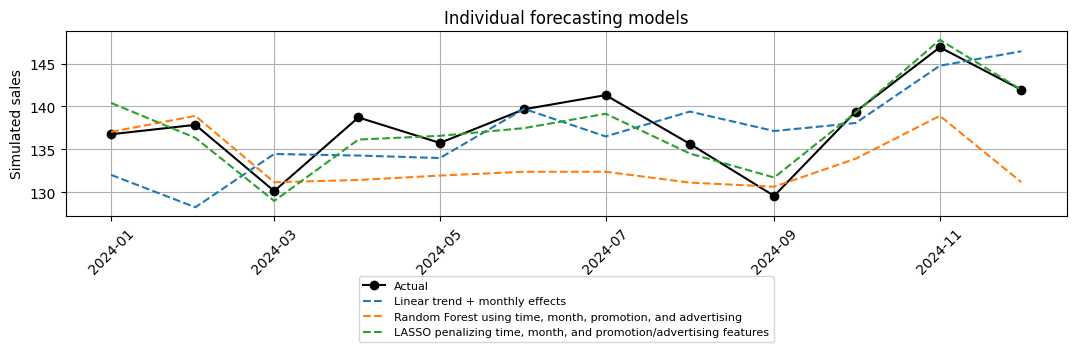

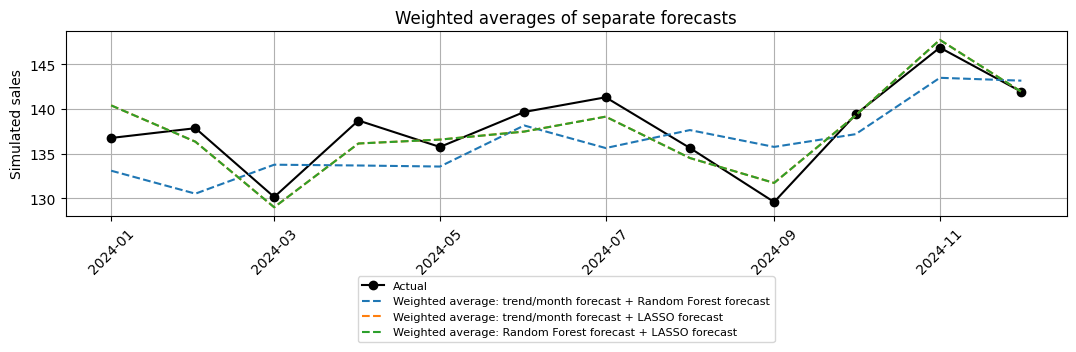

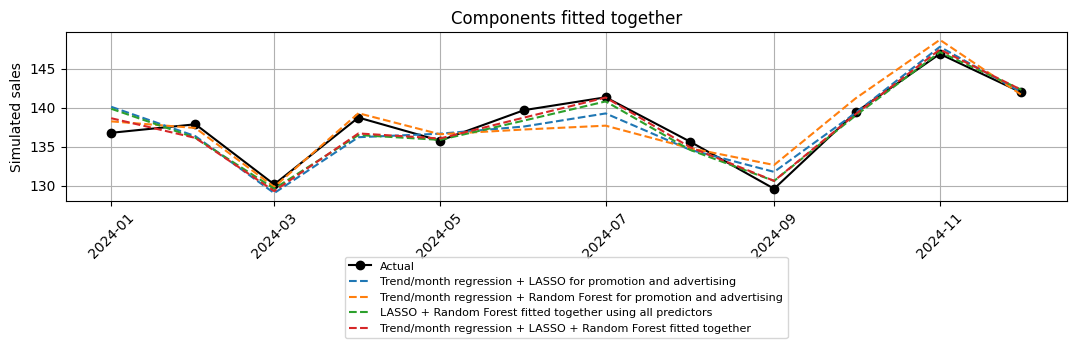

In [14]:
# Separate panels keep all ten forecasts and their labels readable.
groups = [
    (['Trend + seasonality','Random Forest','LASSO'], 'Individual forecasting models'),
    (['Super learner: Random Forest','Super learner: LASSO','RF + LASSO'], 'Weighted averages of separate forecasts'),
    (['Joint LASSO','Joint Random Forest','RF + LASSO fitted together','Time + RF + LASSO'], 'Components fitted together')]
for names, title in groups:
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(forecast_table.index, y_test, 'o-', color='black', label='Actual')
    for name in names:
        ax.plot(forecast_table.index, forecast_table[name], '--', label=MODEL_LABELS[name])
    ax.set(title=title, ylabel='Simulated sales')
    ax.tick_params(axis='x',rotation=45)
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5,-.3))
    plt.tight_layout(); plt.show()
